In [183]:
import importlib
import statistics
import pandas as pd

import solver.mrv_backtracking as mrv_backtracking
import data.data as puzzle_data

from validator import (
    validate_dimensions,
    validate_regions,
    validate_rows,
    validate_columns,
    validate_region_constraints,
    validate_diagonal_constraints
)

import experiments.mrv_validation_experiment as mrv_validation_experiment
import experiments.mrv_benchmark as mrv_benchmark
import experiments.comparison as comparison_module


# Reload modules
for module in [
    mrv_backtracking,
    mrv_validation_experiment,
    mrv_benchmark,
    comparison_module
]:
    importlib.reload(module)

## 5. Backtracking with MRV

### 5.1 Mathematical Idea of MRV

The Minimum Remaining Values (MRV) heuristic is a variable-selection strategy used in constraint satisfaction problems (CSPs). Unlike basic backtracking, which processes variables in a fixed order, MRV selects the unassigned variable with the smallest remaining domain.

In Meowdoku, each coloured region represents a variable. Its domain consists of all cells in that region where a cat can still legally be placed.

Let \(R_k\) represent an unassigned region and \(D(R_k)\) its set of legal candidate cells. MRV selects the region with the smallest domain:

$$
R^* = \text{the region } R_k \text{ for which } |D(R_k)| \text{ is smallest}
$$

Here, \(U\) represents the set of unassigned regions, and \(|D(R_k)|\) represents the number of legal candidate cells in region \(R_k\).

For example, suppose three unassigned regions have the following numbers of legal candidate cells:

$$
|D(R_1)| = 5,\quad |D(R_2)| = 2,\quad |D(R_3)| = 4
$$

MRV selects region \(R_2\), because it has only two legal candidate cells.

If an unassigned region has no legal candidate cells, the current partial solution cannot be completed. The algorithm can immediately backtrack rather than exploring other possibilities.

The purpose of MRV is to reduce unnecessary search by prioritising the most constrained regions. In this project, I will compare its performance with basic backtracking to investigate whether this strategy reduces recursive calls, backtracks, and execution time.

### 5.2 MRV Algorithm and Implementation

The Minimum Remaining Values (MRV) algorithm improves basic backtracking by changing the order in which variables are selected. Instead of processing regions in a fixed order, it selects the unassigned region with the smallest number of currently legal candidate cells.

In this implementation, each coloured region represents a variable, and its domain consists of all cells where a cat can legally be placed. Let \(D(R_k)\) denote the current domain of region \(R_k\). The MRV selection rule can be expressed as

$$
R^* = \underset{R_k \in U}{\operatorname{arg\,min}} \ |D(R_k)|,
$$

where \(U\) is the set of regions that have not yet been assigned a cat.

The function `get_legal_candidates()` determines the available cells for a region by checking whether a placement satisfies the row, column, and diagonal constraints. The function `select_mrv_region()` examines all unassigned regions and selects the one with the smallest candidate domain.

If a region has no legal candidates, then

$$
|D(R_k)| = 0,
$$

which indicates that the current partial assignment cannot lead to a valid solution. The algorithm therefore returns to an earlier decision and tries another candidate.

The recursive function `mrv_backtrack()` attempts each candidate cell in the selected region. If a placement leads to a complete valid solution, the algorithm returns that solution. Otherwise, it removes the placement and continues searching.

The main difference from basic backtracking is the variable-selection strategy. Basic backtracking follows a predetermined region order, whereas MRV dynamically selects the most constrained region at every recursive step.

This strategy follows the principle of addressing the most restrictive decisions first. By prioritising regions with fewer available choices, MRV can identify contradictions earlier and reduce unnecessary exploration of the search tree.

In [184]:
puzzles = {
    name.replace("puzzle_", ""): value
    for name, value in vars(puzzle_data).items()
    if name.startswith("puzzle_") and isinstance(value, dict)
}

puzzle = puzzles["165"]

board_size = puzzle["board_size"]
regions = puzzle["regions"]

solution = [
    [0 for _ in range(board_size)]
    for _ in range(board_size)
]

region_ids = sorted({
    region_id
    for row in regions
    for region_id in row
})

for region_id in region_ids:
    candidates = mrv_backtracking.get_legal_candidates(
        regions,
        region_id,
        solution
    )

    print(f"Region {region_id}: {len(candidates)} candidates")

Region 0: 32 candidates
Region 1: 10 candidates
Region 2: 7 candidates
Region 3: 4 candidates
Region 4: 6 candidates
Region 5: 6 candidates
Region 6: 9 candidates
Region 7: 7 candidates
Region 8: 13 candidates
Region 9: 6 candidates


In [185]:
selected_region, candidates = (
    mrv_backtracking.select_mrv_region(
        regions,
        region_ids,
        solution
    )
)

print("Selected region:", selected_region)
print("Number of candidates:", len(candidates))
print("Candidate cells:", candidates)

Selected region: 3
Number of candidates: 4
Candidate cells: [(1, 5), (1, 6), (1, 7), (1, 8)]


In [186]:
puzzle = puzzles["165"]

board_size = puzzle["board_size"]
regions = puzzle["regions"]

solution = [
    [0 for _ in range(board_size)]
    for _ in range(board_size)
]

region_ids = sorted({
    region_id
    for row in regions
    for region_id in row
})

stats = {
    "recursive_calls": 0,
    "backtracks": 0
}

result = mrv_backtracking.mrv_backtrack(
    regions,
    region_ids,
    solution,
    stats
)

print("Solution found:", result is not None)
print("Recursive calls:", stats["recursive_calls"])
print("Backtracks:", stats["backtracks"])

for row in result:
    print(row)

Solution found: True
Recursive calls: 46
Backtracks: 35
[0, 0, 0, 0, 1, 0, 0, 0, 0, 0]
[0, 0, 0, 0, 0, 0, 0, 0, 1, 0]
[0, 0, 0, 0, 0, 0, 1, 0, 0, 0]
[0, 0, 0, 0, 0, 0, 0, 0, 0, 1]
[0, 0, 1, 0, 0, 0, 0, 0, 0, 0]
[0, 0, 0, 0, 0, 1, 0, 0, 0, 0]
[0, 0, 0, 0, 0, 0, 0, 1, 0, 0]
[1, 0, 0, 0, 0, 0, 0, 0, 0, 0]
[0, 0, 0, 1, 0, 0, 0, 0, 0, 0]
[0, 1, 0, 0, 0, 0, 0, 0, 0, 0]


In [187]:
# Build a puzzle copy with the MRV solution
test_puzzle = {
    **puzzles["165"],
    "solution": result
}

checks = {
    "Dimensions": validate_dimensions(test_puzzle),
    "Regions": validate_regions(test_puzzle),
    "Rows": validate_rows(test_puzzle),
    "Columns": validate_columns(test_puzzle),
    "Region constraints": validate_region_constraints(test_puzzle),
    "Diagonal constraints": validate_diagonal_constraints(test_puzzle)
}

for check, passed in checks.items():
    print(f"{check}: {passed}")

print("All checks passed:", all(checks.values()))

Dimensions: True
Regions: True
Rows: True
Columns: True
Region constraints: True
Diagonal constraints: True
All checks passed: True


### 5.3 Testing and Validation

After implementing MRV, I tested the algorithm on all ten puzzles in the dataset. Each puzzle was solved independently, and the resulting solution was checked using the validation functions developed earlier in the project.

The validation process checked the board dimensions, region structure, and placement constraints. In particular, every row, column, and coloured region had to contain exactly one cat. Additionally, no two cats could touch diagonally. The fixed cat in Puzzle 181 was also preserved.

MRV successfully found a solution for all ten puzzles, and all validation checks passed.

Mathematically, a returned solution \(X\) was accepted only if it satisfied all the constraints defined in Section 2. In particular,

$$
\sum_{j=1}^{n} x_{ij} = 1
\qquad \forall i,
$$

$$
\sum_{i=1}^{n} x_{ij} = 1
\qquad \forall j,
$$

and

$$
\sum_{(i,j)\in R_k} x_{ij} = 1
\qquad \forall R_k \in \mathcal{R}.
$$

The diagonal non-touching constraints were also checked for every pair of diagonally adjacent cells.

The successful validation confirms that the MRV implementation produced valid solutions for the selected dataset. This is important because performance measurements are meaningful only when the algorithms solve the same problems while respecting the same constraints.

In [188]:
mrv_validation_results = (
    mrv_validation_experiment.validate_all_puzzles_mrv(puzzles)
)

mrv_validation_table = pd.DataFrame(mrv_validation_results)

mrv_validation_table

,Puzzle ID,Solution found,All checks passed
0,165,True,True
1,166,True,True
2,170,True,True
3,174,True,True
4,177,True,True
5,178,True,True
6,179,True,True
7,180,True,True
8,181,True,True
9,182,True,True


### 5.4 Benchmarking Methodology

I evaluated the performance of MRV using the same ten puzzles and benchmarking procedure as for basic backtracking. Each puzzle was solved five times to reduce the influence of temporary variations in execution time.

I recorded three performance metrics:

1. **Execution time:** the time required by the solver to find the first complete solution, measured using Python's `time.perf_counter()` (Python Software Foundation, n.d.).

2. **Recursive calls:** the number of times the recursive solving function was executed.

3. **Backtracks:** the number of tentative placements that had to be undone after leading to an unsuccessful search path.

For execution time, I calculated the median of the five runs for each puzzle. If the measured execution times are represented by

$$
T_1, T_2, \ldots, T_5,
$$

the reported execution time is

$$
T_{\mathrm{median}}
=
\operatorname{median}(T_1,T_2,T_3,T_4,T_5).
$$

The recursive call and backtrack counts were consistent across repetitions because the candidate ordering and algorithm behaviour remained deterministic.

The benchmark measured only the solving process. Initialising the board and preparing the input data were excluded from the execution time.

Using the same puzzles, repetition count, and performance metrics for both algorithms allows a direct comparison of their computational behaviour.

In [189]:
mrv_all_results = {}

for puzzle_id, puzzle in puzzles.items():

    mrv_all_results[puzzle_id] = (
        mrv_benchmark.benchmark_mrv_puzzle(
            puzzle,
            repetitions=5
        )
    )

print("MRV benchmarking completed.")

MRV benchmarking completed.


### 5.5 Benchmark Results

The MRV algorithm successfully solved all ten puzzles. The benchmark results show considerable variation in computational effort between puzzles, even when their board dimensions are identical.

The number of recursive calls ranged from 8 to 159, while the number of backtracks ranged from 0 to 148. Puzzle 182 required the greatest search effort under MRV, with 159 recursive calls and 148 backtracks. In contrast, Puzzle 181 required only 8 recursive calls and no backtracking.

The median execution times also varied between puzzles. Puzzle 181 had the shortest median execution time, while Puzzle 182 had the longest.

These differences indicate that board size alone does not determine the computational difficulty of a puzzle. The arrangement of regions and the interaction between placement constraints also influence the search process.

The results are presented below.

In [196]:
import json
import data.data as puzzle_data

with open("data/basic_results.json", "r") as file:
    basic_results = json.load(file)

with open("data/mrv_results.json", "r") as file:
    mrv_data = json.load(file)

mrv_results = mrv_data["mrv"]

puzzles = {
    name.replace("puzzle_", ""): value
    for name, value in vars(puzzle_data).items()
    if name.startswith("puzzle_") and isinstance(value, dict)
}

In [198]:
mrv_summary = []

for puzzle_id, runs in mrv_all_results.items():

    mrv_summary.append({
        "Puzzle ID": puzzle_id,
        "Board Size": puzzles[puzzle_id]["board_size"],
        "Median Time (seconds)": statistics.median(
            run["execution_time"] for run in runs
        ),
        "Recursive Calls": statistics.median(
            run["recursive_calls"] for run in runs
        ),
        "Backtracks": statistics.median(
            run["backtracks"] for run in runs
        )
    })

mrv_results_table = pd.DataFrame(mrv_summary)

mrv_results_table

,Puzzle ID,Board Size,Median Time (seconds),Recursive Calls,Backtracks
0,165,10,0.007862,46,35
1,166,10,0.007725,79,68
2,170,10,0.004304,58,47
3,174,9,0.003093,50,40
4,177,9,0.002921,50,40
5,178,10,0.005425,63,52
6,179,10,0.000834,11,0
7,180,10,0.001217,18,7
8,181,8,0.000304,8,0
9,182,10,0.009356,159,148


### 5.6 Comparison with Basic Backtracking

To evaluate the effect of the Minimum Remaining Values (MRV) heuristic, I compared its performance with the basic backtracking algorithm using the same ten puzzles and three performance metrics: recursive calls, backtracks, and execution time.

The comparison was performed on a puzzle-by-puzzle basis. For each metric, I used the median of the five benchmark runs.

#### Recursive Calls

The most significant difference between the algorithms appears in the number of recursive calls. MRV required fewer recursive calls for every puzzle in the dataset.

Across all ten puzzles, basic backtracking performed a total of 30,054 recursive calls, whereas MRV performed only 542.

The percentage reduction in recursive calls can be calculated as

$$
\text{Reduction} =
\frac{C_{\mathrm{basic}}-C_{\mathrm{MRV}}}
{C_{\mathrm{basic}}}\times 100\%,
$$

where \(C_{\mathrm{basic}}\) and \(C_{\mathrm{MRV}}\) represent the total number of recursive calls made by the two algorithms.

Substituting the measured values gives

$$
\text{Reduction} =
\frac{30054-542}{30054}\times 100\%
\approx 98.20\%.
$$

This means that MRV reduced the total number of recursive calls by approximately \(98.2\%\) on the selected dataset.

The largest individual improvement occurred in Puzzle 177, where the number of recursive calls decreased from 17,694 to 50. This demonstrates how selecting the most constrained region first can substantially reduce unnecessary exploration of the search tree.

#### Backtracks

The number of backtracks was also lower for MRV on every puzzle.

Basic backtracking performed a total of 30,048 backtracks, compared with 437 for MRV. This corresponds to a reduction of approximately

$$
\frac{30048-437}{30048}\times 100\%
\approx 98.55\%.
$$

The result suggests that MRV not only reduces the number of recursive calls but also reduces the number of unsuccessful placements that must be undone.

#### #### Execution Time

Unlike recursive calls and backtracks, execution time did not show a uniform improvement.

MRV was faster on three puzzles but slower on seven. The most noticeable improvement occurred in Puzzle 177, where the median execution time decreased from approximately \(0.0791\) seconds to \(0.0072\) seconds.

However, MRV took longer on Puzzles 165, 166, 170, 178, 179, 181, and 182. This can be explained by the additional computational work required to calculate legal candidate cells and select the region with the smallest remaining domain.

Therefore, reducing the search space does not necessarily guarantee shorter execution time. The overhead introduced by the heuristic can outweigh its benefits on some puzzles.

The execution-time comparison is presented using a logarithmic vertical axis because the measured times differ considerably in magnitude. This scale makes both smaller and larger values easier to compare.

Overall, MRV substantially reduced the search effort on this dataset, but its effect on actual execution time depended on the structure of each puzzle.

In [192]:
importlib.reload(comparison_module)

comparison = comparison_module.create_comparison(
    basic_results,
    mrv_results,
    puzzles
)

comparison

,Puzzle ID,Basic Calls,MRV Calls,Basic Time,MRV Time,Basic Backtracks,MRV Backtracks
0,165,1143,46,0.005702,0.018176,1132,35
1,166,1461,79,0.009390,0.019706,1450,68
2,170,2603,58,0.012563,0.013258,2592,47
3,174,2575,50,0.011186,0.008050,2565,40
4,177,17694,50,0.079078,0.007182,17684,40
5,178,1230,63,0.006031,0.012879,1219,52
6,179,62,11,0.000295,0.001950,51,0
7,180,2831,18,0.013396,0.002496,2820,7
8,181,28,8,0.000086,0.000672,19,0
9,182,427,159,0.002005,0.017532,416,148


The following table and figures provide a direct comparison of the measured performance of both algorithms across all ten puzzles.

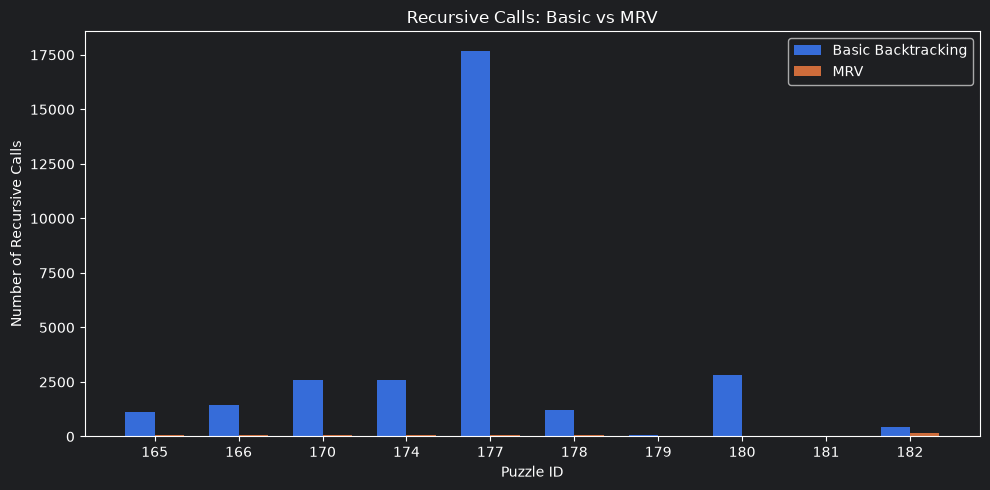

In [193]:
comparison_module.plot_comparison(
    comparison,
    "Basic Calls",
    "MRV Calls",
    "Recursive Calls: Basic vs MRV",
    "Number of Recursive Calls"
)

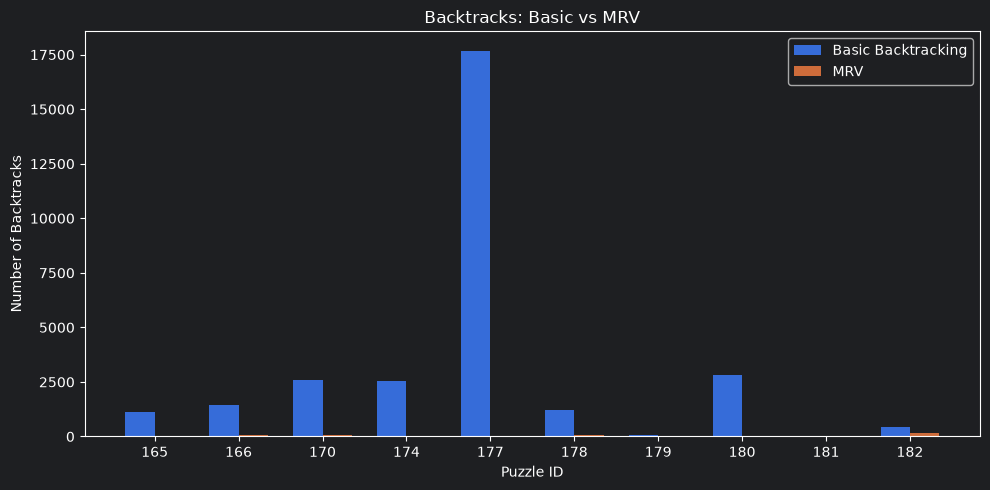

In [194]:
comparison_module.plot_comparison(
    comparison,
    "Basic Backtracks",
    "MRV Backtracks",
    "Backtracks: Basic vs MRV",
    "Number of Backtracks"
)

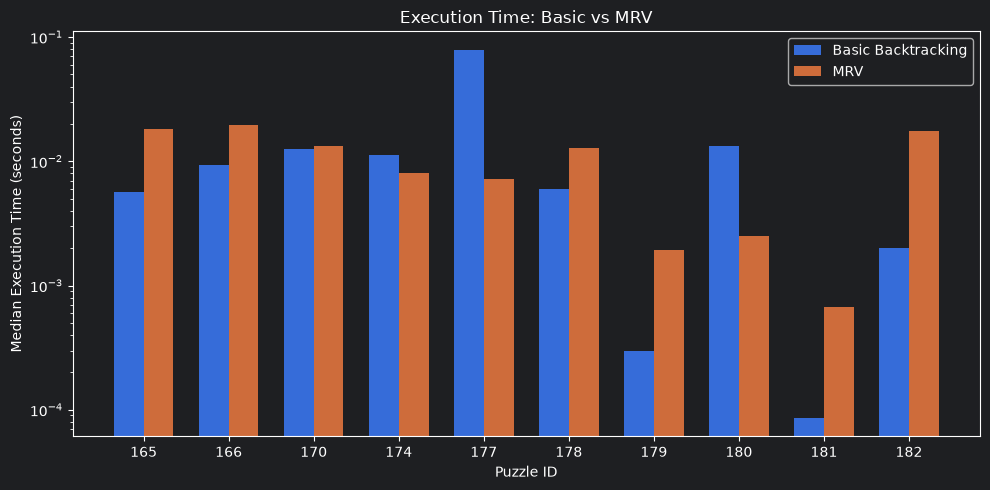

In [195]:
comparison_module.plot_comparison(
    comparison,
    "Basic Time",
    "MRV Time",
    "Execution Time: Basic vs MRV",
    "Median Execution Time (seconds)",
    log_scale=True
)

### 5.7 Discussion and Interpretation

The experimental results provide evidence that the Minimum Remaining Values (MRV) heuristic can substantially improve the search efficiency of a backtracking algorithm for Meowdoku puzzles.

My first hypothesis was that MRV would reduce the number of recursive calls compared with basic backtracking. The results strongly support this hypothesis. MRV required fewer recursive calls for all ten puzzles, reducing the total from 30,054 to 542, which represents an improvement of approximately \(98.2\%\).

This improvement can be explained by the variable-selection strategy. Basic backtracking processes regions in a predetermined order, without considering how constrained each region has become. In contrast, MRV selects the region with the fewest legal candidate cells. This prioritises decisions with fewer available alternatives and allows contradictions to be identified earlier.

The second hypothesis was that MRV would reduce the number of backtracks. This was also supported by the results. The total number of backtracks decreased from 30,048 to 437, corresponding to a reduction of approximately \(98.55\%\). This indicates that choosing more constrained regions first can prevent the algorithm from exploring many unsuccessful placement combinations.

The third hypothesis concerned execution time. I expected MRV to be faster on more difficult puzzles, although the additional candidate calculations could introduce overhead. The results partially support this hypothesis. MRV was faster on six puzzles and slower on four.

Puzzle 177 provides the clearest example of the benefits of MRV. Basic backtracking required 17,694 recursive calls and approximately (0.0791) seconds, whereas MRV required only 50 calls and approximately (0.0072) seconds. This suggests that the original fixed region order was particularly inefficient for this puzzle.

However, Puzzle 182 demonstrates that fewer recursive calls do not necessarily result in shorter execution time. MRV reduced the number of calls from 427 to 159, but its median execution time increased from approximately \(0.0044\) seconds to \(0.0175\) seconds. The additional work required to calculate legal candidate domains and select the next region can therefore outweigh the reduction in search effort.

These observations highlight the distinction between the size of the search process and the computational cost of each step. Recursive calls and backtracks measure aspects of search effort, while execution time also reflects the overhead of the algorithm's operations.

#### Limitations of the Experiment

Although the results demonstrate a substantial improvement in search efficiency, several limitations should be considered.

First, the dataset contains only ten real Meowdoku puzzles. Although these puzzles have different board dimensions and region arrangements, they cannot be considered a representative sample of every possible Meowdoku puzzle.

Second, only one basic backtracking strategy and one MRV implementation were evaluated. Other variable-selection strategies or additional constraint-propagation techniques might produce different results.

Third, execution times were measured on a single computer using Python. Since the measured times are relatively small, background processes, system load, and interpreter overhead may influence individual measurements. Using five repetitions and reporting the median reduces, but does not eliminate, these effects.

Finally, the experiment evaluates the time required to find the first complete solution. It does not measure the time required to establish whether a puzzle has a unique solution or to enumerate all possible solutions.

#### Overall Interpretation

Despite these limitations, the results consistently show that MRV reduces the search effort required to solve the selected puzzles. The most convincing evidence is the reduction in recursive calls and backtracks across all ten instances.

The execution-time results provide a more nuanced conclusion: MRV is highly effective at reducing search, but its additional computational overhead means that fewer recursive calls do not always translate into faster execution.

Therefore, the experiment supports the use of MRV as an effective variable-selection heuristic for this Meowdoku dataset, while also demonstrating why algorithm performance should be evaluated using multiple metrics rather than execution time alone.

### 5.8 Interim Conclusion

In this part of the project, I implemented and evaluated the Minimum Remaining Values (MRV) heuristic as an improvement to basic backtracking for solving Meowdoku puzzles.

The MRV algorithm dynamically selects the unassigned region with the fewest legal candidate cells. This strategy prioritises the most constrained decisions and helps identify unsuccessful search paths earlier.

The experimental results demonstrated a substantial reduction in search effort across all ten puzzles. Compared with basic backtracking, MRV reduced the total number of recursive calls by approximately \(98.2\%\) and the total number of backtracks by approximately \(98.55\%\).

However, the execution-time results showed that improved search efficiency does not always guarantee faster execution. The additional calculations required by MRV introduced overhead, which made it slower on four of the ten puzzles.

Overall, the experiment supports MRV as an effective strategy for reducing the search effort required to solve the selected Meowdoku puzzles. It also demonstrates the importance of evaluating algorithms using multiple performance metrics.

The comparison provides a foundation for understanding how constraint-based search strategies influence computational performance and highlights the relationship between mathematical problem-solving techniques and practical algorithm implementation.